In [9]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
from transformers import logging
logging.set_verbosity(50)   # completely silent

import torch
from inference_cltot import predict_cltot

from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*')

%load_ext autoreload
%autoreload 2

np.random.seed(30)
torch.manual_seed(0)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
data = [('5-Fluorouracil','C1=C(C(=O)NC(=O)N1)F',26.0),
('6-Mercaptopurine','C1=NC2=C(N1)C(=S)N=CN2',15.0),
('9-Aminocamptothecin','CCC1(C2=C(COC1=O)C(=O)N3CC4=CC5=C(C=CC=C5N=C4C3=C2)N)O',6.5),
('Abacavir','C1CC1NC2=C3C(=NC(=N2)N)N(C=N3)C4CC(C=C4)CO',13.0),
('Acecainide','CCN(CC)CCNC(=O)C1=CC=C(C=C1)NC(=O)C',4.0),
('Acetaminophen','CC(=O)NC1=CC=C(C=C1)O',5.0),
('Acetazolamide','CC(=O)NC1=NN=C(S1)S(=O)(=O)N',0.64999998),
('Acetylsalicylic Acid','CC(=O)OC1=CC=CC=C1C(=O)O',12.0),
('Acivicin','C1C(ON=C1Cl)C(C(=O)O)N',0.69),
('Actisomide','CC1=NC(=O)C(C2N1CCCC2)(CCN(C(C)C)C(C)C)C3=CC=CC=C3',6.79),
('Acyclovir','C1=NC2=C(N1COCCO)N=C(NC2=O)N',4.6999998),
('Adefovir','C1=NC(=C2C(=N1)N(C=N2)CCOCP(=O)(O)O)N',3.7),
('Albuterol','CC(C)(C)NCC(C1=CC(=C(C=C1)O)CO)O',7.8000002),
('Alfentanil','CCC(=O)N(C1=CC=CC=C1)C2(CCN(CC2)CCN3C(=O)N(N=N3)CC)COC',3.9000001),
('Allopurinol','C1=NNC2=C1C(=O)NC=N2',11.0),]
data_df = pd.DataFrame(data=data, columns=['Name', 'smiles', 'CLtot'])
smis = data_df['smiles'].tolist()
y_true = data_df['CLtot'].apply(np.log10)
data_df['log_CLtot'] = y_true

#### **Predict the Clearance values for single SMILES**

In [13]:
y_pred = predict_cltot(smis[0])
y_pred[0].pop('image')
y_pred

[{'smiles': 'C1=C(C(=O)NC(=O)N1)F',
  'NN': 0.8253,
  'RF': 0.6062,
  'SVM': 0.7385,
  'XGB': 0.6215}]

#### **Predict the Clearance values for multiple SMILES**

In [3]:
y_pred = predict_cltot(smis)
df_pred = pd.DataFrame(y_pred).drop(columns=['image', 'smiles'])
data_df = pd.concat([data_df, df_pred], axis=1)
data_df

,Name,smiles,CLtot,log_CLtot,NN,RF,SVM,XGB
0,5-Fluorouracil,C1=C(C(=O)NC(=O)N1)F,26.00,1.414973,0.8253,0.6062,0.7385,0.6215
1,6-Mercaptopurine,C1=NC2=C(N1)C(=S)N=CN2,15.00,1.176091,0.8877,0.8238,0.8498,0.8026
2,9-Aminocamptothecin,CCC1(C2=C(COC1=O)C(=O)N3CC4=CC5=C(C=CC=C5N=C4C...,6.50,0.812913,0.2713,0.5053,0.3655,0.4872
3,Abacavir,C1CC1NC2=C3C(=NC(=N2)N)N(C=N3)C4CC(C=C4)CO,13.00,1.113943,0.8167,0.7545,0.8766,0.7279
4,Acecainide,CCN(CC)CCNC(=O)C1=CC=C(C=C1)NC(=O)C,4.00,0.602060,0.5391,0.6491,0.5003,0.6621
5,Acetaminophen,CC(=O)NC1=CC=C(C=C1)O,5.00,0.698970,0.3326,0.3107,0.2294,0.3169
6,Acetazolamide,CC(=O)NC1=NN=C(S1)S(=O)(=O)N,0.65,-0.187087,0.0395,0.0631,0.0171,0.1802
7,Acetylsalicylic Acid,CC(=O)OC1=CC=CC=C1C(=O)O,12.00,1.079181,0.1138,0.0621,0.0232,0.0605
8,Acivicin,C1C(ON=C1Cl)C(C(=O)O)N,0.69,-0.161151,0.1404,0.1786,0.2104,0.1815
9,Actisomide,CC1=NC(=O)C(C2N1CCCC2)(CCN(C(C)C)C(C)C)C3=CC=C...,6.79,0.831870,0.2422,0.4915,0.3330,0.5532


In [4]:
img = y_pred[2].pop('image')
y_pred[2]

{'smiles': 'CCC1(C2=C(COC1=O)C(=O)N3CC4=CC5=C(C=CC=C5N=C4C3=C2)N)O',
 'NN': 0.2713,
 'RF': 0.5053,
 'SVM': 0.3655,
 'XGB': 0.4872}

In [5]:
y_pred = predict_cltot(smis)
img = y_pred[0].pop('image')
y_pred[0]

{'smiles': 'C1=C(C(=O)NC(=O)N1)F',
 'NN': 0.8253,
 'RF': 0.6062,
 'SVM': 0.7385,
 'XGB': 0.6215}

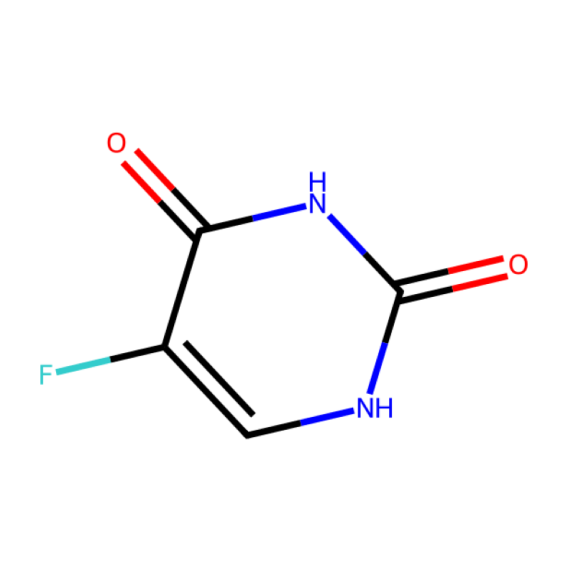

In [6]:
from IPython.display import SVG, display

display(SVG(img))